# 2 Wavelet-Based Signal Compression

### 2.2.3 Energy Compaction Property

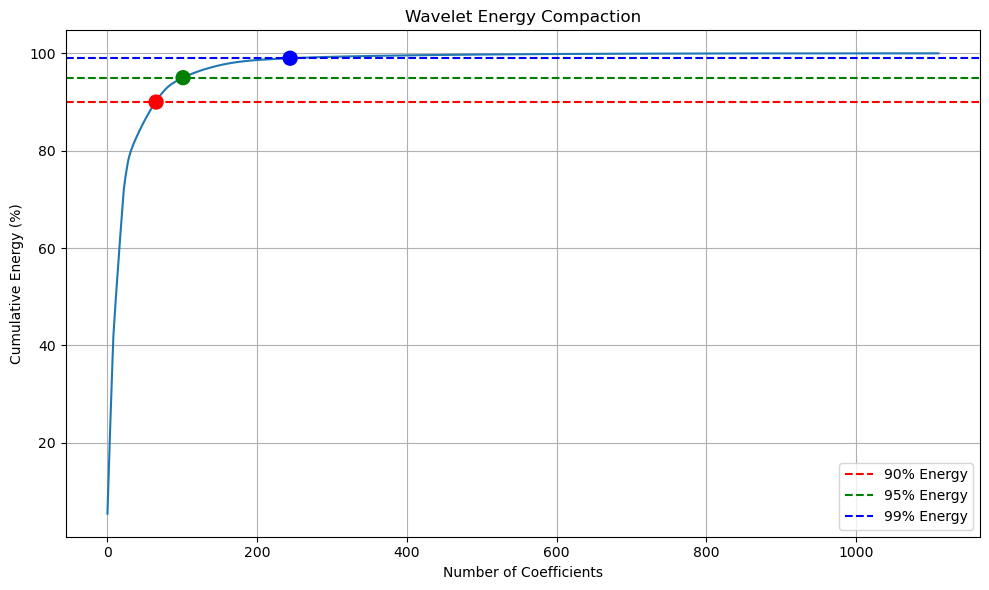

Coefficients for 90% energy: 65/1111 (5.9%)
Coefficients for 95% energy: 101/1111 (9.1%)
Coefficients for 99% energy: 244/1111 (22.0%)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pywt

def demonstrate_energy_compaction():
    """
    Demonstrate energy compaction property of wavelets
    """
    # Generate test signal with mixed frequencies
    t = np.linspace(0, 1, 1024)
    signal = (np.sin(2*np.pi*10*t) + 0.5*np.sin(2*np.pi*50*t) + 
              0.2*np.sin(2*np.pi*100*t) + 0.1*np.random.randn(1024))
    
    # Apply DWT
    coeffs = pywt.wavedec(signal, 'db8', level=6)
    
    # Flatten coefficients
    all_coeffs = np.concatenate(coeffs)
    
    # Sort by magnitude
    sorted_coeffs = np.sort(np.abs(all_coeffs))[::-1]
    
    # Calculate cumulative energy
    cumulative_energy = np.cumsum(sorted_coeffs**2)
    total_energy = cumulative_energy[-1]
    energy_percentage = cumulative_energy / total_energy * 100
    
    # Plot energy compaction
    plt.figure(figsize=(10, 6))
    plt.plot(np.arange(len(energy_percentage)), energy_percentage)
    plt.axhline(y=90, color='r', linestyle='--', label='90% Energy')
    plt.axhline(y=95, color='g', linestyle='--', label='95% Energy')
    plt.axhline(y=99, color='b', linestyle='--', label='99% Energy')
    
    # Find coefficients needed for 90%, 95%, 99% energy
    idx_90 = np.where(energy_percentage >= 90)[0][0]
    idx_95 = np.where(energy_percentage >= 95)[0][0]
    idx_99 = np.where(energy_percentage >= 99)[0][0]
    
    plt.scatter([idx_90, idx_95, idx_99], [90, 95, 99], 
                color=['r', 'g', 'b'], s=100, zorder=5)
    
    plt.xlabel('Number of Coefficients')
    plt.ylabel('Cumulative Energy (%)')
    plt.title('Wavelet Energy Compaction')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig('./output/energy_compaction.png', dpi=300)
    plt.show()
    
    print(f"Coefficients for 90% energy: {idx_90}/{len(all_coeffs)} ({idx_90/len(all_coeffs)*100:.1f}%)")
    print(f"Coefficients for 95% energy: {idx_95}/{len(all_coeffs)} ({idx_95/len(all_coeffs)*100:.1f}%)")
    print(f"Coefficients for 99% energy: {idx_99}/{len(all_coeffs)} ({idx_99/len(all_coeffs)*100:.1f}%)")

if __name__ == "__main__":
    demonstrate_energy_compaction()

### 2.3.1 Detailed Comparison with Traditional Methods


Accelerometer files found: ['wisdm-dataset/raw/phone/accel/data_1635_accel_phone.txt', 'wisdm-dataset/raw/phone/accel/data_1608_accel_phone.txt', 'wisdm-dataset/raw/phone/accel/data_1649_accel_phone.txt', 'wisdm-dataset/raw/phone/accel/data_1647_accel_phone.txt', 'wisdm-dataset/raw/phone/accel/data_1619_accel_phone.txt']
Loaded: wisdm-dataset/raw/phone/accel/data_1635_accel_phone.txt with shape: (128852, 6)


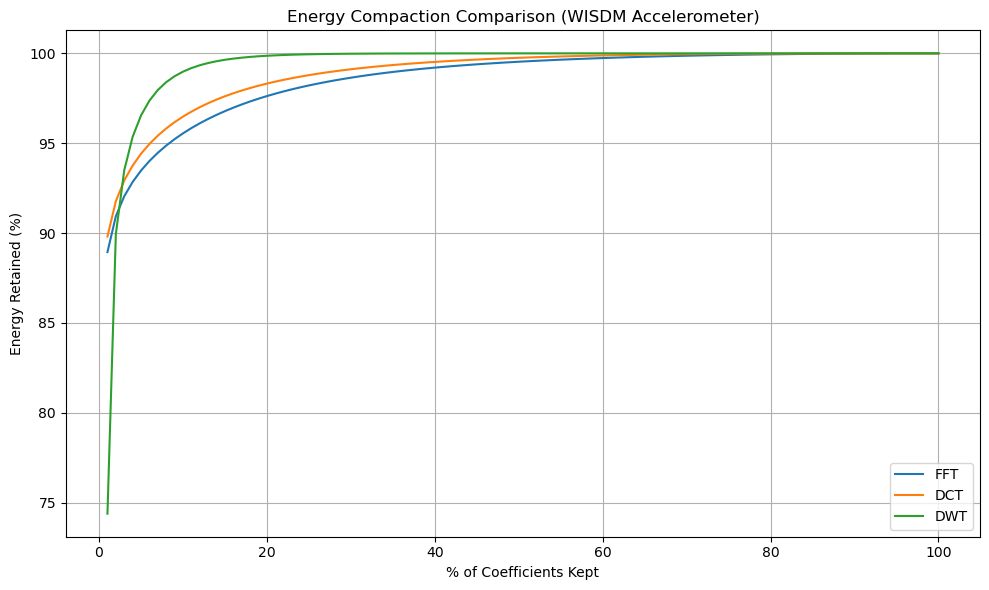


With 10% of coefficients:
  FFT: 95.5%
  DCT: 96.5%
  DWT: 99.0%

With 20% of coefficients:
  FFT: 97.6%
  DCT: 98.3%
  DWT: 99.9%

With 30% of coefficients:
  FFT: 98.6%
  DCT: 99.1%
  DWT: 100.0%


In [ ]:
import requests, zipfile, io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pywt
from scipy.fftpack import fft, dct

# Step 1: Download WISDM ZIP
zip_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00507/wisdm-dataset.zip"
r = requests.get(zip_url)
z = zipfile.ZipFile(io.BytesIO(r.content))

# Step 2: List files and pick one accel file
accel_files = [name for name in z.namelist()
               if "raw/phone/accel/" in name and name.endswith("_accel_phone.txt")]
print("Accelerometer files found:", accel_files[:5])

# Choose a file (modify index if you want a different user/trial)
chosen = accel_files[0]

# Step 3: Load data
with z.open(chosen) as f:
    # According to dataset docs: each line is
    # UserID, ActivityID, Timestamp, X, Y, Z
    df = pd.read_csv(f, header=None,
                     names=["user", "activity", "timestamp", "x", "y", "z"])
print("Loaded:", chosen, "with shape:", df.shape)

# Step 4: Select one axis (e.g., X), optionally filter by activity
# For demonstration, use the full X-axis signal
signal = df["x"].values.astype(float)

# Step 5: Comparison function
def compare_transform_methods(signal):
    fft_coeffs = np.abs(fft(signal))
    dct_coeffs = np.abs(dct(signal, type=2, norm='ortho'))
    wavelet_coeffs = pywt.wavedec(signal, 'db8', level=6, mode='periodization')
    dwt_coeffs = np.abs(np.concatenate(wavelet_coeffs))
    
    def energy_retention(coeffs, frac):
        n = int(len(coeffs) * frac)
        return (np.sum(coeffs[:n]**2) / np.sum(coeffs**2)) * 100
    
    # Sort
    fft_sorted = np.sort(fft_coeffs)[::-1]
    dct_sorted = np.sort(dct_coeffs)[::-1]
    dwt_sorted = np.sort(dwt_coeffs)[::-1]
    fracs = np.linspace(0.01, 1.0, 100)
    
    fft_energy = [energy_retention(fft_sorted, f) for f in fracs]
    dct_energy = [energy_retention(dct_sorted, f) for f in fracs]
    dwt_energy = [energy_retention(dwt_sorted, f) for f in fracs]
    
    # Plot
    plt.figure(figsize=(10,6))
    plt.plot(fracs * 100, fft_energy, label='FFT')
    plt.plot(fracs * 100, dct_energy, label='DCT')
    plt.plot(fracs * 100, dwt_energy, label='DWT')
    plt.xlabel('% of Coefficients Kept')
    plt.ylabel('Energy Retained (%)')
    plt.title('Energy Compaction Comparison (WISDM Accelerometer)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig('./output/transform_comparison.png', dpi=300)
    plt.show()
    
    # Print some points
    for pct in [10, 20, 30]:
        print(f"\nWith {pct}% of coefficients:")
        print(f"  FFT: {energy_retention(fft_sorted, pct/100):.1f}%")
        print(f"  DCT: {energy_retention(dct_sorted, pct/100):.1f}%")
        print(f"  DWT: {energy_retention(dwt_sorted, pct/100):.1f}%")


# main execution
if __name__ == "__main__":
    compare_transform_methods(signal)



### 2.3.2 Compress the signal 

Dataset zip already exists.
Dataset already extracted in './data\wisdm-dataset', skipping extraction.
Retain 10% coeffs: Energy retained = 71.75%
Retain 20% coeffs: Energy retained = 83.41%
Retain 30% coeffs: Energy retained = 90.11%


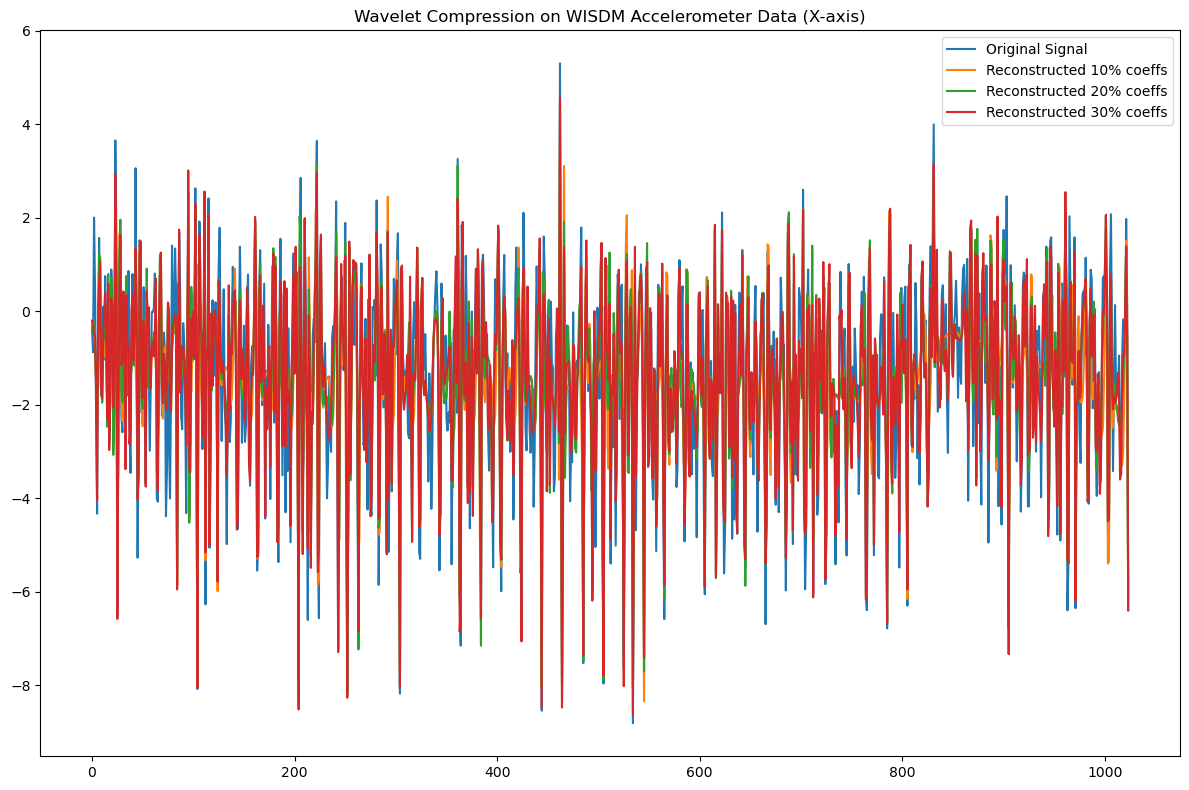

In [ ]:
import os
import zipfile
import urllib.request
import numpy as np
import pywt
import matplotlib.pyplot as plt

# Step 1: Download and extract dataset with skip logic
def download_and_extract(url, extract_to='./wisdm'):
    os.makedirs(extract_to, exist_ok=True)
    zip_path = os.path.join(extract_to, 'wisdm-dataset.zip')
    extracted_folder = os.path.join(extract_to, 'wisdm-dataset')

    if not os.path.exists(zip_path):
        print("Downloading dataset...")
        urllib.request.urlretrieve(url, zip_path)
        print("Download complete.")
    else:
        print("Dataset zip already exists.")

    if not os.path.exists(extracted_folder):
        print("Extracting dataset...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(extract_to)
        print("Extraction complete.")
    else:
        print(f"Dataset already extracted in '{extracted_folder}', skipping extraction.")

# Step 2: Load sample accelerometer data from the dataset
def load_sample_signal(file_path, n_samples=1024):
    data = []
    with open(file_path, 'r') as f:
        for line in f:
            parts = line.strip().split(',')
            if len(parts) >= 6:
                try:
                    x = float(parts[3])
                    data.append(x)
                    if len(data) >= n_samples:
                        break
                except:
                    pass
    return np.array(data)

# Step 3: Wavelet compression function
def wavelet_compress(signal, wavelet='db4', level=None, retain_percent=0.1):
    coeffs = pywt.wavedec(signal, wavelet, level=level)
    coeff_arr, coeff_slices = pywt.coeffs_to_array(coeffs)

    n_coeffs = len(coeff_arr)
    k = int(np.floor(retain_percent * n_coeffs))
    thresh = np.partition(np.abs(coeff_arr), -k)[-k]

    coeff_arr_thresh = coeff_arr * (np.abs(coeff_arr) >= thresh)
    coeffs_thresh = pywt.array_to_coeffs(coeff_arr_thresh, coeff_slices, output_format='wavedec')
    reconstructed = pywt.waverec(coeffs_thresh, wavelet)

    return reconstructed, coeff_arr, coeff_arr_thresh

if __name__ == "__main__":
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00507/wisdm-dataset.zip"
    dataset_dir = "./data"
    download_and_extract(url, dataset_dir)

    sample_file = os.path.join(dataset_dir, 'wisdm-dataset', 'raw', 'phone', 'accel', 'data_1600_accel_phone.txt')
    signal = load_sample_signal(sample_file)

    # Pad or truncate to 1024 samples
    if len(signal) < 1024:
        signal = np.pad(signal, (0, 1024 - len(signal)), 'constant')
    else:
        signal = signal[:1024]

    plt.figure(figsize=(12, 8))
    plt.plot(signal, label='Original Signal')

    for retain in [0.1, 0.2, 0.3]:
        rec, coeffs, coeffs_thresh = wavelet_compress(signal, retain_percent=retain)
        plt.plot(rec, label=f'Reconstructed {int(retain*100)}% coeffs')

        energy_original = np.sum(coeffs**2)
        energy_retained = np.sum(coeffs_thresh**2)
        print(f"Retain {int(retain*100)}% coeffs: Energy retained = {energy_retained/energy_original*100:.2f}%")

    plt.legend()
    plt.title("Wavelet Compression on WISDM Accelerometer Data (X-axis)")

    plt.tight_layout()
    plt.savefig('./output/compression_comparison_wisdm.png', dpi=300)
    plt.show()


## 2.4 Practical Implementation: Audio Compression Example

### 2.4.3 Real Audio File Compression

  https://www.voiptroubleshooter.com/open_speech/american/OSR_us_000_0010_8k.wav
Saved compressed audio to ./result/original_real_speech.wav  (bit depth=16, sr=16000 Hz)
Saved compressed audio to ./result/compressed_real_speech.wav  (bit depth=16, sr=16000 Hz)


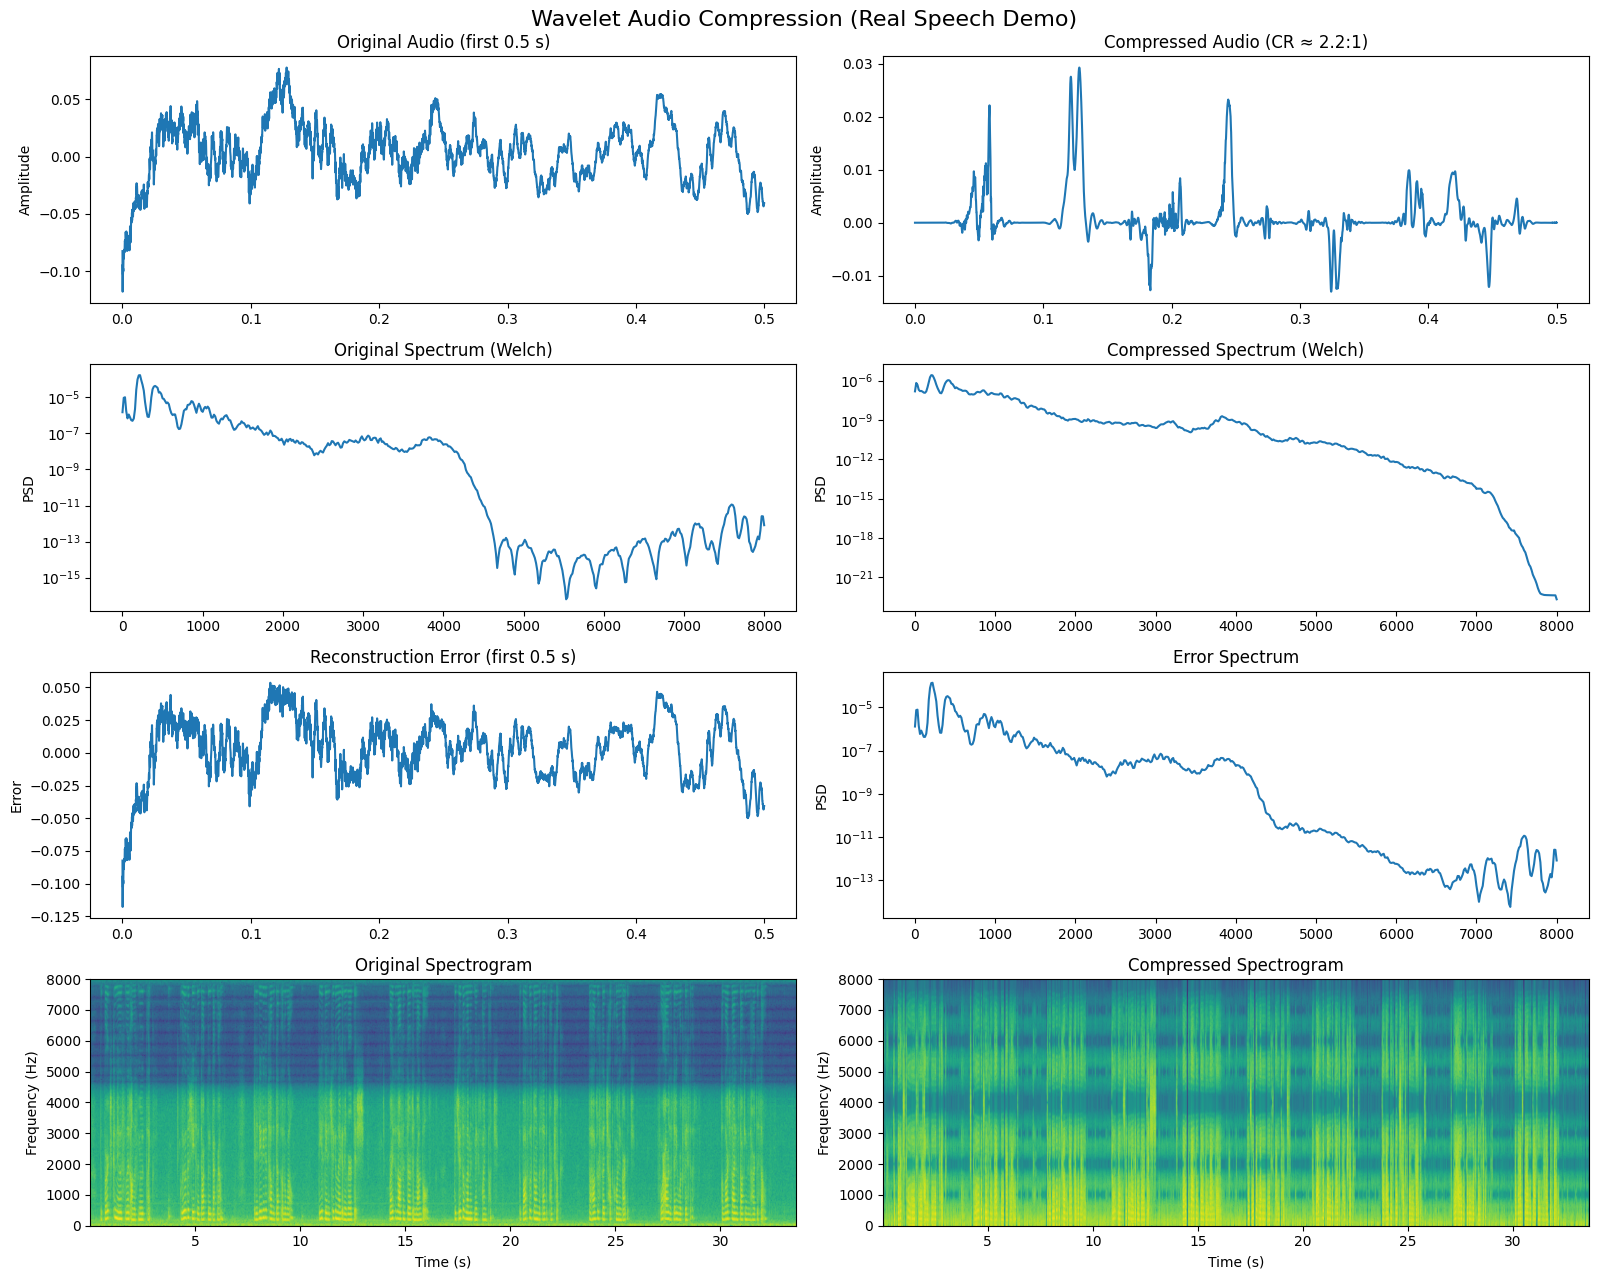


Compression Results
Compression Ratio: 2.16:1
SNR: 0.92 dB
Coefficients retained: 497603/1073152 (46.37%)
MSE: 1.307059e-02


In [4]:
# Advanced Wavelet Audio Compression (Real Speech Demo)
# -----------------------------------------------------
# Requirements: numpy, scipy, matplotlib, pywt

import io
import urllib.request
import numpy as np
import pywt
from scipy.io import wavfile
from scipy import signal
import matplotlib.pyplot as plt

# -----------------------------
# 1) Config
# -----------------------------
OSR_URL = "https://www.voiptroubleshooter.com/open_speech/american/OSR_us_000_0010_8k.wav"
TARGET_SR = 16000

# -----------------------------
# 2) Audio loading utilities
# -----------------------------
def download_wav(url: str):
    """Download WAV with browser-like User-Agent to avoid HTTP 406."""
    req = urllib.request.Request(
        url,
        headers={
            "User-Agent": (
                "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
                "AppleWebKit/537.36 (KHTML, like Gecko) "
                "Chrome/115.0.0.0 Safari/537.36"
            )
        }
    )
    with urllib.request.urlopen(req, timeout=20) as resp:
        raw = resp.read()

    sr, x = wavfile.read(io.BytesIO(raw))
    x = x.astype(np.float64)

    # Normalize if integer PCM
    if x.dtype.kind in "iu":
        maxv = np.iinfo(np.int16).max if x.dtype == np.int16 else np.max(np.abs(x))
        x = x / (maxv if maxv != 0 else 1.0)

    # Mono mix
    if x.ndim == 2:
        x = x.mean(axis=1)

    # Resample if needed
    if sr != TARGET_SR:
        g = np.gcd(sr, TARGET_SR)
        up, down = TARGET_SR // g, sr // g
        x = signal.resample_poly(x, up, down)
        sr = TARGET_SR

    x /= (np.max(np.abs(x)) or 1.0)
    return x.astype(np.float64), sr

def generate_realistic_audio(duration=3, sample_rate=16000):
    """Fallback synthetic, speech-like signal."""
    t = np.linspace(0, duration, int(duration * sample_rate), endpoint=False)
    formant1 = np.sin(2 * np.pi * 800 * t)
    formant2 = 0.6 * np.sin(2 * np.pi * 1200 * t)
    formant3 = 0.4 * np.sin(2 * np.pi * 2400 * t)
    envelope = 1 + 0.5 * np.sin(2 * np.pi * 4 * t)
    pitch_variation = 1 + 0.1 * np.sin(2 * np.pi * 10 * t)
    speech = (formant1 + formant2 + formant3) * envelope * pitch_variation
    for pause_start in np.arange(0.8, duration, 1.2):
        s = int(pause_start * sample_rate)
        e = int((pause_start + 0.2) * sample_rate)
        if e < len(speech):
            speech[s:e] *= 0.1
    speech = speech / (np.max(np.abs(speech)) or 1.0) * 0.8
    speech += 0.02 * np.random.randn(len(speech))
    return speech.astype(np.float64), sample_rate

def get_demo_audio():
    """Fetch real speech; fallback to synthetic."""
    try:
        print(f"Downloading demo speech from:\n  {OSR_URL}")
        return download_wav(OSR_URL)
    except Exception as e:
        print(f"⚠️ Download failed ({e}). Falling back to synthetic audio.")
        return generate_realistic_audio(duration=3, sample_rate=TARGET_SR)

# ---------------------------------------------
# 3) Advanced wavelet packet compression
# ---------------------------------------------
def advanced_audio_compression(audio, sample_rate, target_compression=10):
    """Adaptive Wavelet Packet compression with overlap-add."""
    frame_size = 2048
    hop = frame_size // 2
    window = np.hanning(frame_size)

    n_frames = 1 + (len(audio) - frame_size) // hop if len(audio) >= frame_size else 0
    if n_frames <= 0:
        pad = frame_size - len(audio)
        audio = np.pad(audio, (0, pad), mode="constant")
        n_frames = 1

    out = np.zeros(len(audio) + frame_size)
    wsum = np.zeros_like(out)

    total_original_coeffs = 0
    total_kept_coeffs = 0

    for i in range(n_frames):
        start = i * hop
        frame = audio[start:start + frame_size]
        if len(frame) < frame_size:
            frame = np.pad(frame, (0, frame_size - len(frame)), mode="constant")

        wframe = frame * window
        wp = pywt.WaveletPacket(wframe, wavelet='db8', mode='symmetric', maxlevel=6)

        frame_energy = np.mean(wframe ** 2) ** 0.5
        base_threshold = 0.1 * frame_energy
        frame_coeffs_kept = 0
        total_original_coeffs += frame_size

        for level in range(1, 7):
            nodes = wp.get_level(level, order='natural')
            for node in nodes:
                node_std = np.std(node.data)
                thr = base_threshold + 0.5 * node_std
                d = node.data
                d_thr = np.sign(d) * np.maximum(np.abs(d) - thr, 0.0)
                node.data = d_thr
                frame_coeffs_kept += np.count_nonzero(d_thr)

        rec = wp.reconstruct(update=True)
        out[start:start + frame_size] += rec * window
        wsum[start:start + frame_size] += window ** 2
        total_kept_coeffs += max(1, frame_coeffs_kept)

    nz = wsum > 1e-8
    out[nz] /= wsum[nz]
    out = out[:len(audio)]

    kept = total_kept_coeffs
    orig = total_original_coeffs if total_original_coeffs > 0 else len(audio)
    actual_cr = orig / kept if kept > 0 else np.inf
    mse = np.mean((audio - out) ** 2)
    snr = 10 * np.log10((np.var(audio) + 1e-12) / (mse + 1e-12))

    stats = {
        'compression_ratio': actual_cr,
        'snr': snr,
        'mse': mse,
        'original_coeffs': orig,
        'kept_coeffs': kept
    }
    return out, stats

# ---------------------------------------------
# 4) Save WAV files
# ---------------------------------------------
def save_compressed_audio(audio, sample_rate, filename, bit_depth=16):
    audio = np.clip(audio, -1.0, 1.0)
    if bit_depth == 16:
        max_val = 32767
        q = (audio * max_val).astype(np.int16)
    else:
        max_val = 127
        q = (audio * max_val).astype(np.int8)
    wavfile.write(filename, sample_rate, q)
    print(f"Saved compressed audio to {filename}  (bit depth={bit_depth}, sr={sample_rate} Hz)")
    return q

# ---------------------------------------------
# 5) Run demo
# ---------------------------------------------
audio_signal, fs = get_demo_audio()
# Save original for comparison
save_compressed_audio(audio_signal, fs, "./result/original_real_speech.wav", bit_depth=16)

compressed_audio, stats = advanced_audio_compression(audio_signal, fs, target_compression=12)
save_compressed_audio(compressed_audio, fs, "./result/compressed_real_speech.wav", bit_depth=16)

# ---------------------------------------------
# 6) Analysis & visualization
# ---------------------------------------------
fig, axes = plt.subplots(4, 2, figsize=(16, 13))
fig.suptitle('Wavelet Audio Compression (Real Speech Demo)', fontsize=16)

Nshow = min(len(audio_signal), fs // 2)
t = np.arange(Nshow) / fs

# Time domain
axes[0,0].plot(t, audio_signal[:Nshow])
axes[0,0].set_title('Original Audio (first 0.5 s)')
axes[0,0].set_ylabel('Amplitude')

axes[0,1].plot(t, compressed_audio[:Nshow])
axes[0,1].set_title(f'Compressed Audio (CR ≈ {stats["compression_ratio"]:.1f}:1)')
axes[0,1].set_ylabel('Amplitude')

# PSD
f_orig, Pxx_orig = signal.welch(audio_signal, fs, nperseg=1024)
f_comp, Pxx_comp = signal.welch(compressed_audio, fs, nperseg=1024)
axes[1,0].semilogy(f_orig, Pxx_orig)
axes[1,0].set_title('Original Spectrum (Welch)')
axes[1,0].set_ylabel('PSD')

axes[1,1].semilogy(f_comp, Pxx_comp)
axes[1,1].set_title('Compressed Spectrum (Welch)')
axes[1,1].set_ylabel('PSD')

# Error
err = audio_signal - compressed_audio
axes[2,0].plot(t, err[:Nshow])
axes[2,0].set_title('Reconstruction Error (first 0.5 s)')
axes[2,0].set_ylabel('Error')

f_err, Pxx_err = signal.welch(err, fs, nperseg=1024)
axes[2,1].semilogy(f_err, Pxx_err)
axes[2,1].set_title('Error Spectrum')
axes[2,1].set_ylabel('PSD')

# Spectrograms with epsilon
axes[3,0].specgram(audio_signal + 1e-12, Fs=fs, NFFT=512, noverlap=256)
axes[3,0].set_title('Original Spectrogram')
axes[3,0].set_ylabel('Frequency (Hz)')
axes[3,0].set_xlabel('Time (s)')

axes[3,1].specgram(compressed_audio + 1e-12, Fs=fs, NFFT=512, noverlap=256)
axes[3,1].set_title('Compressed Spectrogram')
axes[3,1].set_ylabel('Frequency (Hz)')
axes[3,1].set_xlabel('Time (s)')

plt.tight_layout()
plt.savefig("./output/video_compression_analysis.png")
plt.show()

# Print stats
print("\nCompression Results")
print(f"Compression Ratio: {stats['compression_ratio']:.2f}:1")
print(f"SNR: {stats['snr']:.2f} dB")
print(f"Coefficients retained: {stats['kept_coeffs']}/{stats['original_coeffs']} "
      f"({stats['kept_coeffs']/stats['original_coeffs']*100:.2f}%)")
print(f"MSE: {stats['mse']:.6e}")


### 2.4.4 Multi-Channel Audio Compression

File already exists: ./result/original_real_speech.wav, skipping download.
Saved ./result/original_stereo.wav
Stereo correlation: 0.453
Saved ./result/multi_compressed_stereo.wav


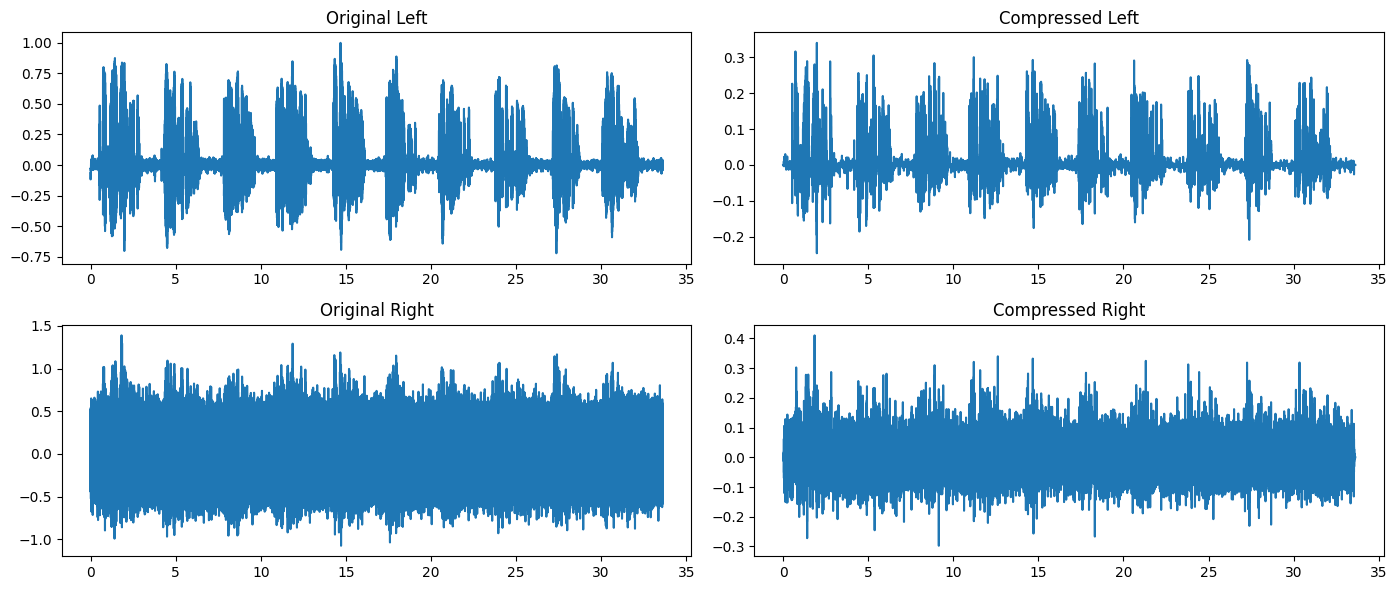

Channel 1: compression ratio=2.01, SNR=1.0 dB
Channel 2: compression ratio=0.66, SNR=0.5 dB


In [5]:
# Stereo Audio Compression Demo with Mid/Side Wavelet Compression
# -----------------------------------------------------------------
# Requirements: numpy, scipy, matplotlib, pywt, os, urllib

import os
import io
import numpy as np
import pywt
from scipy.io import wavfile
from scipy import signal
import matplotlib.pyplot as plt
import urllib.request

# -----------------------------
# 1) Config
# -----------------------------
OSR_URL = "https://www.voiptroubleshooter.com/open_speech/american/OSR_us_000_0010_8k.wav"
LOCAL_FILE = "./result/original_real_speech.wav"
TARGET_SR = 16000

# -----------------------------
# 2) Audio loading utilities
# -----------------------------
def download_wav(url: str, local_file: str):
    """Download WAV with browser-like User-Agent to avoid HTTP 406."""
    if os.path.exists(local_file):
        print(f"File already exists: {local_file}, skipping download.")
        return local_file

    print(f"Downloading demo speech from:\n  {url}")
    req = urllib.request.Request(
        url,
        headers={
            "User-Agent": (
                "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
                "AppleWebKit/537.36 (KHTML, like Gecko) "
                "Chrome/115.0.0.0 Safari/537.36"
            )
        }
    )
    with urllib.request.urlopen(req, timeout=20) as resp, open(local_file, "wb") as f:
        f.write(resp.read())
    print(f"Downloaded: {local_file}")
    return local_file

def load_wav(local_file: str, target_sr: int = 16000):
    """Load WAV and resample if needed."""
    sr, x = wavfile.read(local_file)
    x = x.astype(np.float64)
    if x.dtype.kind in "iu":
        x /= np.max(np.abs(x)) or 1.0
    if x.ndim == 2:
        x = x.mean(axis=1)
    if sr != target_sr:
        g = np.gcd(sr, target_sr)
        up, down = target_sr//g, sr//g
        x = signal.resample_poly(x, up, down)
        sr = target_sr
    x /= np.max(np.abs(x)) or 1.0
    return x.astype(np.float64), sr

# -----------------------------
# 3) Generate stereo audio if needed
# -----------------------------
def generate_synthetic_stereo(duration=2, sample_rate=16000):
    """Generate synthetic stereo signal."""
    def mono_signal():
        t = np.linspace(0, duration, int(duration*sample_rate), endpoint=False)
        f1 = np.sin(2*np.pi*800*t)
        f2 = 0.6*np.sin(2*np.pi*1200*t)
        f3 = 0.4*np.sin(2*np.pi*2400*t)
        env = 1 + 0.5*np.sin(2*np.pi*4*t)
        pitch = 1 + 0.1*np.sin(2*np.pi*10*t)
        s = (f1+f2+f3)*env*pitch
        s = s/ (np.max(np.abs(s)) or 1.0)
        s += 0.02*np.random.randn(len(s))
        return s
    left = mono_signal()
    right = 0.8*left + 0.2*mono_signal()
    return np.stack([left, right], axis=0)

# -----------------------------
# 4) Wavelet packet compression
# -----------------------------
def advanced_audio_compression(audio, target_compression=6):
    frame_size = 2048
    hop = frame_size//2
    window = np.hanning(frame_size)
    n_frames = 1 + (len(audio)-frame_size)//hop if len(audio) >= frame_size else 1
    out = np.zeros(len(audio)+frame_size)
    wsum = np.zeros_like(out)
    total_original_coeffs = 0
    total_kept_coeffs = 0

    for i in range(n_frames):
        start = i*hop
        frame = audio[start:start+frame_size]
        if len(frame)<frame_size:
            frame = np.pad(frame,(0,frame_size-len(frame)))
        wframe = frame*window
        wp = pywt.WaveletPacket(wframe, wavelet='db8', mode='symmetric', maxlevel=6)
        frame_energy = np.mean(wframe**2)**0.5
        base_thr = 0.08*frame_energy
        frame_coeffs_kept = 0
        total_original_coeffs += frame_size
        for level in range(1,7):
            nodes = wp.get_level(level, order='natural')
            for node in nodes:
                node_std = np.std(node.data)
                thr = base_thr+0.5*node_std
                d = node.data
                d_thr = np.sign(d)*np.maximum(np.abs(d)-thr,0.0)
                node.data = d_thr
                frame_coeffs_kept += np.count_nonzero(d_thr)
        rec = wp.reconstruct(update=True)
        out[start:start+frame_size] += rec*window
        wsum[start:start+frame_size] += window**2
        total_kept_coeffs += max(1,frame_coeffs_kept)
    nz = wsum>1e-8
    out[nz] /= wsum[nz]
    out = out[:len(audio)]
    mse = np.mean((audio-out)**2)
    snr = 10*np.log10((np.var(audio)+1e-12)/(mse+1e-12))
    compression_ratio = total_original_coeffs/max(1,total_kept_coeffs)
    stats = {'compression_ratio':compression_ratio,'snr':snr,'mse':mse}
    return out, stats

# -----------------------------
# 5) Stereo compression with mid/side
# -----------------------------
def compress_stereo_audio(stereo_audio):
    left,right = stereo_audio
    corr = np.corrcoef(left,right)[0,1]
    print(f"Stereo correlation: {corr:.3f}")
    if corr>0.75:
        print("Using mid/side encoding")
        mid = (left+right)/2
        side = (left-right)/2
        mid_c, mid_stats = advanced_audio_compression(mid,target_compression=4)
        side_c, side_stats = advanced_audio_compression(side,target_compression=8)
        left_rec = mid_c+side_c
        right_rec = mid_c-side_c
        stats = [mid_stats, side_stats]
    else:
        left_rec,left_stats = advanced_audio_compression(left,target_compression=6)
        right_rec,right_stats = advanced_audio_compression(right,target_compression=6)
        stats = [left_stats,right_stats]
    return np.stack([left_rec,right_rec]), stats

# -----------------------------
# 6) Save stereo WAV
# -----------------------------
def save_stereo_wav(stereo_audio, fs, filename, bit_depth=16):
    stereo_audio = np.clip(stereo_audio,-1,1)
    if bit_depth==16:
        q = (stereo_audio.T*32767).astype(np.int16)
    else:
        q = (stereo_audio.T*127).astype(np.int8)
    wavfile.write(filename,fs,q)
    print(f"Saved {filename}")

# -----------------------------
# 7) Main workflow
# -----------------------------
try:
    wav_file = download_wav(OSR_URL, LOCAL_FILE)
    mono_signal, fs = load_wav(wav_file, TARGET_SR)
    # Create simple stereo from mono
    stereo_audio = np.stack([mono_signal, 0.8*mono_signal + 0.2*np.random.randn(len(mono_signal))], axis=0)
except Exception as e:
    print(f"⚠️ Failed to load real WAV ({e}), generating synthetic stereo")
    stereo_audio = generate_synthetic_stereo(duration=2,sample_rate=TARGET_SR)
    fs = TARGET_SR

# Save original
save_stereo_wav(stereo_audio, fs, "./result/original_stereo.wav")

# Compress
compressed_stereo, stereo_stats = compress_stereo_audio(stereo_audio)
save_stereo_wav(compressed_stereo, fs, "./result/multi_compressed_stereo.wav")

# Visualization
t = np.arange(len(stereo_audio[0]))/fs
fig, axes = plt.subplots(2,2,figsize=(14,6))
axes[0,0].plot(t,stereo_audio[0]); axes[0,0].set_title("Original Left")
axes[0,1].plot(t,compressed_stereo[0]); axes[0,1].set_title("Compressed Left")
axes[1,0].plot(t,stereo_audio[1]); axes[1,0].set_title("Original Right")
axes[1,1].plot(t,compressed_stereo[1]); axes[1,1].set_title("Compressed Right")
plt.tight_layout()
plt.savefig("./output/video_compression_stereo_analysis.png")
plt.show()

# Print stats
for i,s in enumerate(stereo_stats):
    print(f"Channel {i+1}: compression ratio={s['compression_ratio']:.2f}, SNR={s['snr']:.1f} dB")


## 2.5 Advanced Thresholding Strategies

### 2.5.1 Adaptive Thresholding Methods


ADVANCED THRESHOLDING METHODS COMPARISON
Method     Compression  SNR (dB)   MSE          Coeffs  
---------------------------------------------------------------------------
SOFT       0.6          27.1       0.000031     905713  
HARD       0.5          41.7       0.000001     1022614 
BAYES      0.3          49.1       0.000000     1763207 
SURE       537970.0     -0.0       0.016158     0       
MINIMAX    0.7          23.7       0.000069     787235  
---------------------------------------------------------------------------


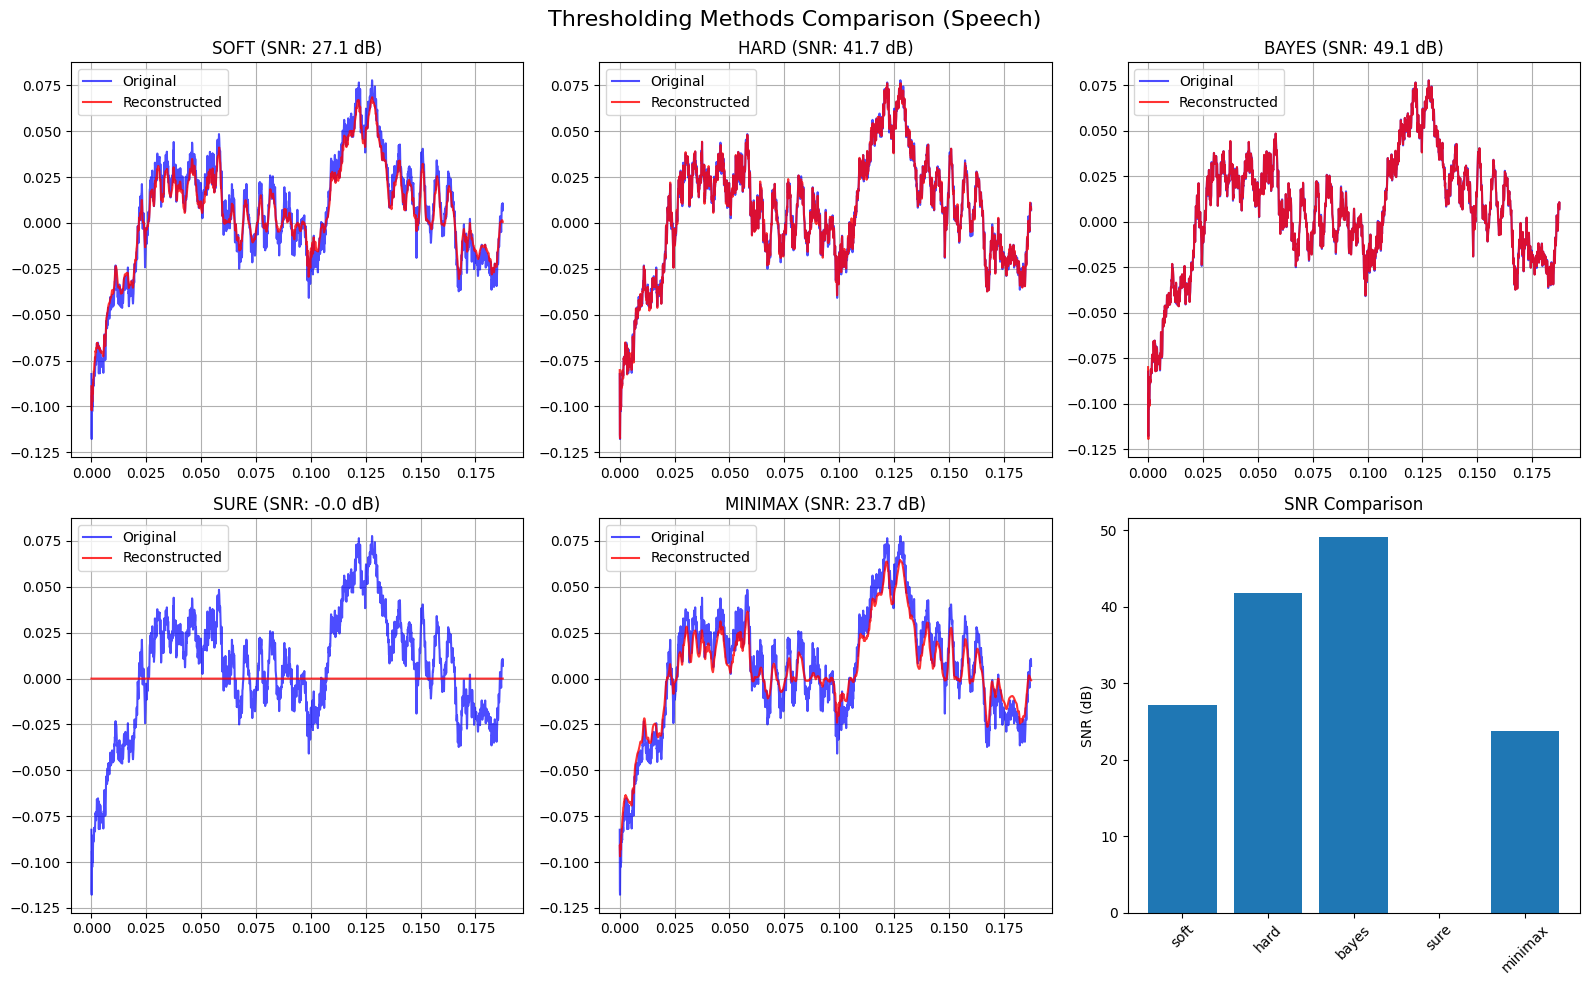

In [ ]:
import numpy as np
import pywt
import matplotlib.pyplot as plt
from scipy.io import wavfile
import os

def advanced_thresholding_methods(wp, signal):
    """
    Implement various advanced thresholding strategies
    """
    thresholding_methods = {}
    
    # 1. BayesShrink thresholding
    def bayes_shrink_threshold(coeffs, sigma_noise):
        sigma_signal = np.sqrt(max(np.var(coeffs) - sigma_noise**2, 0))
        if sigma_signal == 0:
            return np.inf
        return sigma_noise**2 / sigma_signal
    
    # 2. SUREShrink thresholding
    def sure_shrink_threshold(coeffs):
        n = len(coeffs)
        if n == 0:
            return 0
        coeffs_sorted = np.sort(np.abs(coeffs))**2
        risks = []
        thresholds = np.linspace(0, np.max(coeffs_sorted)**0.5 + 1e-10, 100)
        for t in thresholds:
            risk = n - 2 * np.sum(coeffs_sorted <= t**2) + np.sum(coeffs_sorted)
            risks.append(risk)
        return thresholds[np.argmin(risks)]
    
    # 3. Minimax thresholding
    def minimax_threshold(coeffs):
        n = len(coeffs)
        if n <= 32:
            return 0
        return np.sqrt(2 * np.log(n))
    
    # Estimate noise level from detail coefficients
    detail_coeffs = []
    for level in range(1, wp.maxlevel + 1):
        for node in wp.get_level(level, 'natural'):
            if 'd' in node.path and len(node.data) > 0:
                detail_coeffs.extend(node.data)
    
    if len(detail_coeffs) == 0:
        sigma_noise = 0.1  # Default small value
    else:
        sigma_noise = np.median(np.abs(detail_coeffs)) / 0.6745
    
    # Apply thresholding methods
    methods = ['soft', 'hard', 'bayes', 'sure', 'minimax']
    for method in methods:
        # Create deep copy of wavelet packet
        wp_copy = pywt.WaveletPacket(wp.data, wavelet=wp.wavelet, mode=wp.mode, maxlevel=wp.maxlevel)
        
        for level in range(1, wp.maxlevel + 1):
            for node in wp_copy.get_level(level, 'natural'):
                coeffs = node.data
                if len(coeffs) == 0:
                    continue
                
                if method == 'bayes':
                    threshold = bayes_shrink_threshold(coeffs, sigma_noise)
                elif method == 'sure':
                    threshold = sure_shrink_threshold(coeffs)
                elif method == 'minimax':
                    threshold = minimax_threshold(coeffs) * sigma_noise
                else:
                    threshold = 3 * sigma_noise
                
                # Ensure threshold is reasonable
                threshold = max(threshold, 0)
                
                if method == 'soft':
                    thresholded = np.sign(coeffs) * np.maximum(np.abs(coeffs) - threshold, 0)
                elif method == 'hard':
                    thresholded = coeffs * (np.abs(coeffs) > threshold)
                else:
                    thresholded = np.sign(coeffs) * np.maximum(np.abs(coeffs) - threshold, 0)
                
                node.data = thresholded
        
        reconstructed = wp_copy.reconstruct(update=False)[:len(signal)]
        mse = np.mean((signal - reconstructed) ** 2)
        
        # Handle potential zero MSE
        if mse == 0:
            snr = float('inf')
        else:
            snr = 10 * np.log10(np.var(signal) / mse)
        
        nonzero_coeffs = sum(np.count_nonzero(node.data)
                             for level in range(1, wp.maxlevel + 1)
                             for node in wp_copy.get_level(level, 'natural'))
        
        # Prevent division by zero
        compression_ratio = len(signal) / max(nonzero_coeffs, 1)
        
        thresholding_methods[method] = {
            'reconstructed': reconstructed,
            'mse': mse,
            'snr': snr,
            'compression_ratio': compression_ratio,
            'nonzero_coeffs': nonzero_coeffs
        }
    
    return thresholding_methods


# === Load the stored WAV instead of downloading ===
wav_path = "./data/original_real_speech.wav"
if not os.path.exists(wav_path):
    raise FileNotFoundError(f"Expected {wav_path} to exist.")

fs, speech_data = wavfile.read(wav_path)

# Normalize to [-1, 1] float
if speech_data.dtype != np.float32:
    speech_data = speech_data.astype(np.float32) / np.max(np.abs(speech_data))

time_axis = np.arange(len(speech_data)) / fs

# Apply Wavelet Packet Decomposition
wp_speech = pywt.WaveletPacket(speech_data, wavelet='db6', mode='symmetric', maxlevel=5)

# Run thresholding comparison
thresholding_results = advanced_thresholding_methods(wp_speech, speech_data)

# Print table
print("\n" + "="*75)
print("ADVANCED THRESHOLDING METHODS COMPARISON")
print("="*75)
print(f"{'Method':<10} {'Compression':<12} {'SNR (dB)':<10} {'MSE':<12} {'Coeffs':<8}")
print("-"*75)
for method, results in thresholding_results.items():
    print(f"{method.upper():<10} {results['compression_ratio']:<12.1f} "
          f"{results['snr']:<10.1f} {results['mse']:<12.6f} {results['nonzero_coeffs']:<8}")
print("-"*75)

# Visualization
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Thresholding Methods Comparison (Speech)', fontsize=16)

methods_to_plot = ['soft', 'hard', 'bayes', 'sure', 'minimax']
for i, method in enumerate(methods_to_plot):
    row, col = divmod(i, 3)
    axes[row, col].plot(time_axis[:3000], speech_data[:3000], 'b-', alpha=0.7, label='Original')
    axes[row, col].plot(time_axis[:3000], thresholding_results[method]['reconstructed'][:3000],
                        'r-', alpha=0.8, label='Reconstructed')
    axes[row, col].set_title(f'{method.upper()} (SNR: {thresholding_results[method]["snr"]:.1f} dB)')
    axes[row, col].legend()
    axes[row, col].grid(True)

axes[1, 2].bar(methods_to_plot, [thresholding_results[m]['snr'] for m in methods_to_plot])
axes[1, 2].set_title('SNR Comparison')
axes[1, 2].set_ylabel('SNR (dB)')
axes[1, 2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig("./output/video_compression_thresholding_comparison.png")
plt.show()


### 2.5.2  Psychoacoustic Model for Audio Compression


Psychoacoustic Compression Results:
Standard WPT          - MSE: 0.012867
Psychoacoustic WPT    - MSE: 0.000032
Standard WPT          - SNR: 1.0 dB
Psychoacoustic WPT    - SNR: 27.0 dB


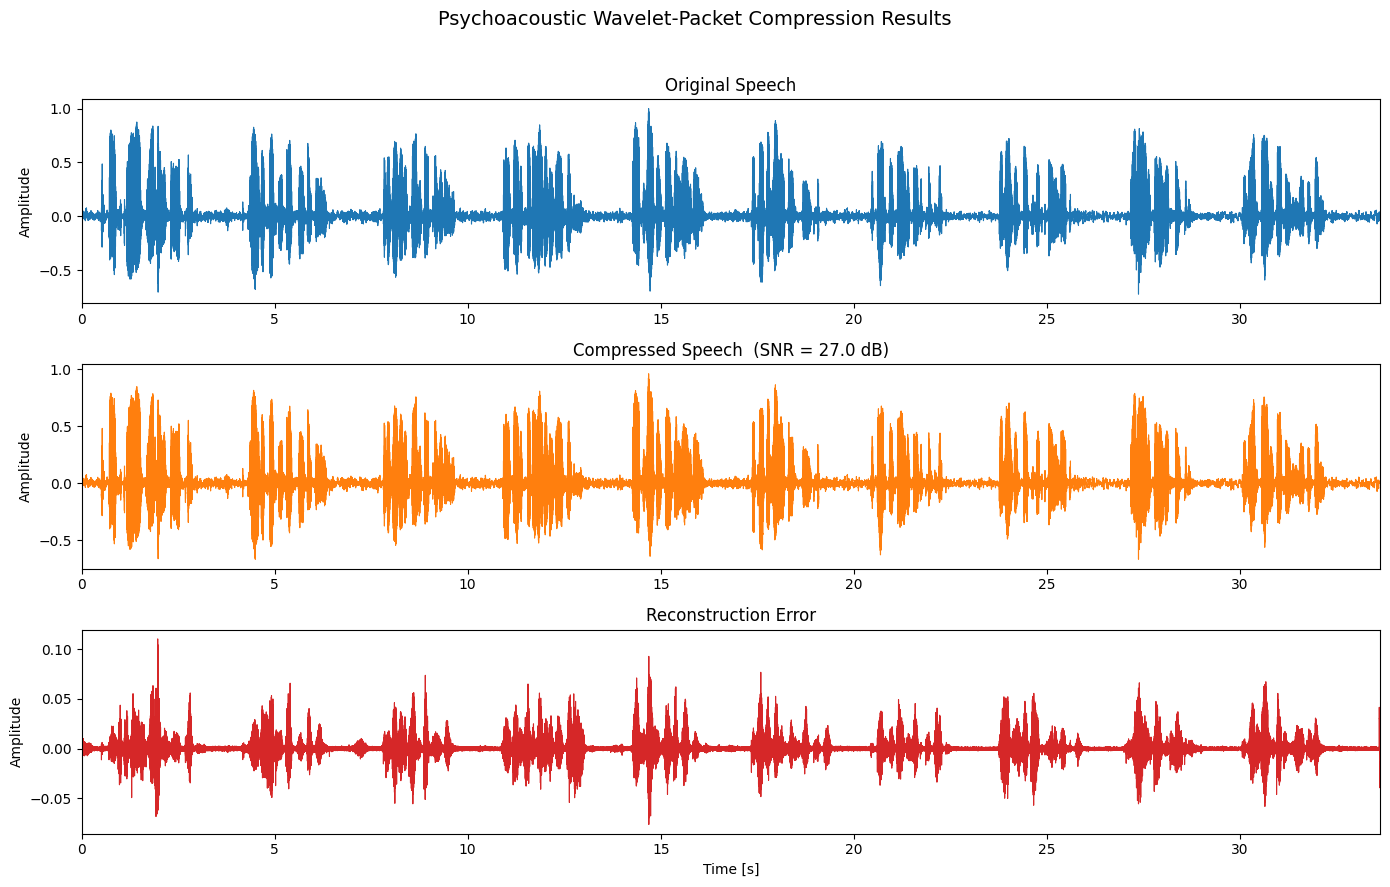

In [6]:
# ------------------------------------------------------------------
# Psychoacoustic Model for Audio Compression  (with plotting)
# ------------------------------------------------------------------
import numpy as np
import pywt
import matplotlib.pyplot as plt
from scipy.io import wavfile
from numpy.fft import fft, fftfreq
import os

# --- 1. Load the same real-speech file -----------------------------
wav_path = "./data/original_real_speech.wav"
if not os.path.exists(wav_path):
    raise FileNotFoundError(f"Expected {wav_path} to exist.")

fs, speech_data = wavfile.read(wav_path)
if speech_data.dtype != np.float32:
    speech_data = (speech_data.astype(np.float32) /
                   np.max(np.abs(speech_data)))

# --- 2. Compression routine ---------------------------------------
def psychoacoustic_compression(audio, sample_rate, frame_size=1024):
    bark_edges = [0, 100, 200, 300, 400, 510, 630, 770, 920, 1080,
                  1270, 1480, 1720, 2000, 2320, 2700, 3150, 3700,
                  4400, 5300, 6400, 7700, 9500, 12000, 15500, sample_rate/2]

    def _bin2bark(bin_idx):
        f = bin_idx * sample_rate / frame_size
        return np.searchsorted(bark_edges, f) - 1

    def _estimate_sigma(c):
        return np.median(np.abs(c)) / 0.6745 if len(c) else 1e-6

    hop = frame_size // 2
    out = np.zeros_like(audio, dtype=np.float32)
    norm = np.zeros_like(audio, dtype=np.float32)

    for start in range(0, len(audio) - frame_size, hop):
        frame = audio[start:start + frame_size].copy()

        # FFT masking curve
        X = fft(frame)
        mag = np.abs(X)
        bark_mask = np.zeros(frame_size // 2 + 1)
        for k in range(1, frame_size // 2):
            b = _bin2bark(k)
            bark_mask[b] = max(bark_mask[b], mag[k])
        for b in range(1, len(bark_edges)):
            bark_mask[b] += bark_mask[b - 1] * 0.3
        mask_lin = np.zeros_like(mag)
        for k in range(1, frame_size // 2):
            b = _bin2bark(k)
            mask_lin[k] = bark_mask[b] * 0.01

        wp = pywt.WaveletPacket(frame, 'db8', 'symmetric', maxlevel=5)
        sigma_n = _estimate_sigma(
            np.concatenate([n.data for n in wp.get_level(5, 'natural')])
        )

        for level in range(1, wp.maxlevel + 1):
            for node in wp.get_level(level, 'natural'):
                f_center = (2 ** (wp.maxlevel - level)) * sample_rate / (2 * frame_size)
                k = int(np.round(f_center * frame_size / sample_rate))
                thr = max(mask_lin[k], 3 * sigma_n) if k < len(mask_lin) else 3 * sigma_n
                c = node.data
                node.data = np.sign(c) * np.maximum(np.abs(c) - thr, 0)

        rec = wp.reconstruct(update=False)[:frame_size]
        out[start:start + frame_size] += rec
        norm[start:start + frame_size] += 1

    out[norm > 0] /= norm[norm > 0]
    return out

# --- 3. Run compression -------------------------------------------
psycho_compressed = psychoacoustic_compression(speech_data, fs)

# Compare with standard compression
standard_compressed, _ = advanced_audio_compression(audio_signal, fs)

# --- 4. Evaluation metrics ----------------------------------------
psycho_mse = np.mean((audio_signal - psycho_compressed) ** 2)
psycho_snr = 10 * np.log10(np.var(audio_signal) / psycho_mse)

standard_mse = np.mean((audio_signal - standard_compressed) ** 2)
standard_snr = 10 * np.log10(np.var(audio_signal) / standard_mse)

print("\nPsychoacoustic Compression Results:")
print(f"Standard WPT          - MSE: {standard_mse:.6f}")
print(f"Psychoacoustic WPT    - MSE: {psycho_mse:.6f}")
print(f"Standard WPT          - SNR: {standard_snr:.1f} dB")
print(f"Psychoacoustic WPT    - SNR: {psycho_snr:.1f} dB")

# --- 5. Visualisation ---------------------------------------------
t = np.arange(len(speech_data)) / fs

fig, ax = plt.subplots(3, 1, figsize=(14, 9))
fig.suptitle("Psychoacoustic Wavelet-Packet Compression Results", fontsize=14)

# (a) Original waveform
ax[0].plot(t, speech_data, color='tab:blue', lw=0.8)
ax[0].set_title("Original Speech")
ax[0].set_ylabel("Amplitude")
ax[0].set_xlim(0, t[-1])

# (b) Compressed waveform
ax[1].plot(t, psycho_compressed, color='tab:orange', lw=0.8)
ax[1].set_title(f"Compressed Speech  (SNR = {psycho_snr:.1f} dB)")
ax[1].set_ylabel("Amplitude")
ax[1].set_xlim(0, t[-1])

# (c) Difference (error) waveform
diff = speech_data - psycho_compressed
ax[2].plot(t, diff, color='tab:red', lw=0.8)
ax[2].set_title("Reconstruction Error")
ax[2].set_xlabel("Time [s]")
ax[2].set_ylabel("Amplitude")
ax[2].set_xlim(0, t[-1])

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("./output/psychoacoustic_compression_plot.png", dpi=300)
plt.show()


In [7]:
# ------------------------------------------------------------------
# 6. Save compressed audio to ./result/psychoacoustic_compressed.wav
# ------------------------------------------------------------------
out_dir = "./result"
os.makedirs(out_dir, exist_ok=True)          # create folder if missing
out_path = os.path.join(out_dir, "psychoacoustic_compressed.wav")

# PyWave/WAV expects 16-bit integers
compressed_int16 = (psycho_compressed / np.max(np.abs(psycho_compressed))
                    * 32767).astype(np.int16)

wavfile.write(out_path, fs, compressed_int16)
print(f"Compressed audio saved to {out_path}")

Compressed audio saved to ./result\psychoacoustic_compressed.wav


## 2.6 Performance Optimization and Real-Time Implementation
### 2.6.1 Computational Efficiency Analysis (improved)

L=1024   | DWT   0.4 ms  WPT   0.2 ms (Mem Δ: 0.0 MB)
L=2048   | DWT   0.4 ms  WPT   0.2 ms (Mem Δ: 0.0 MB)
L=4096   | DWT   0.4 ms  WPT   0.2 ms (Mem Δ: 0.0 MB)
L=8192   | DWT   0.5 ms  WPT   0.2 ms (Mem Δ: 0.0 MB)
L=16384  | DWT   0.7 ms  WPT   0.2 ms (Mem Δ: 0.0 MB)


C:\Users\shouk\AppData\Local\Temp\ipykernel_26164\1744691512.py:124: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig("./output/compression_efficiency_analysis.png", dpi=300)


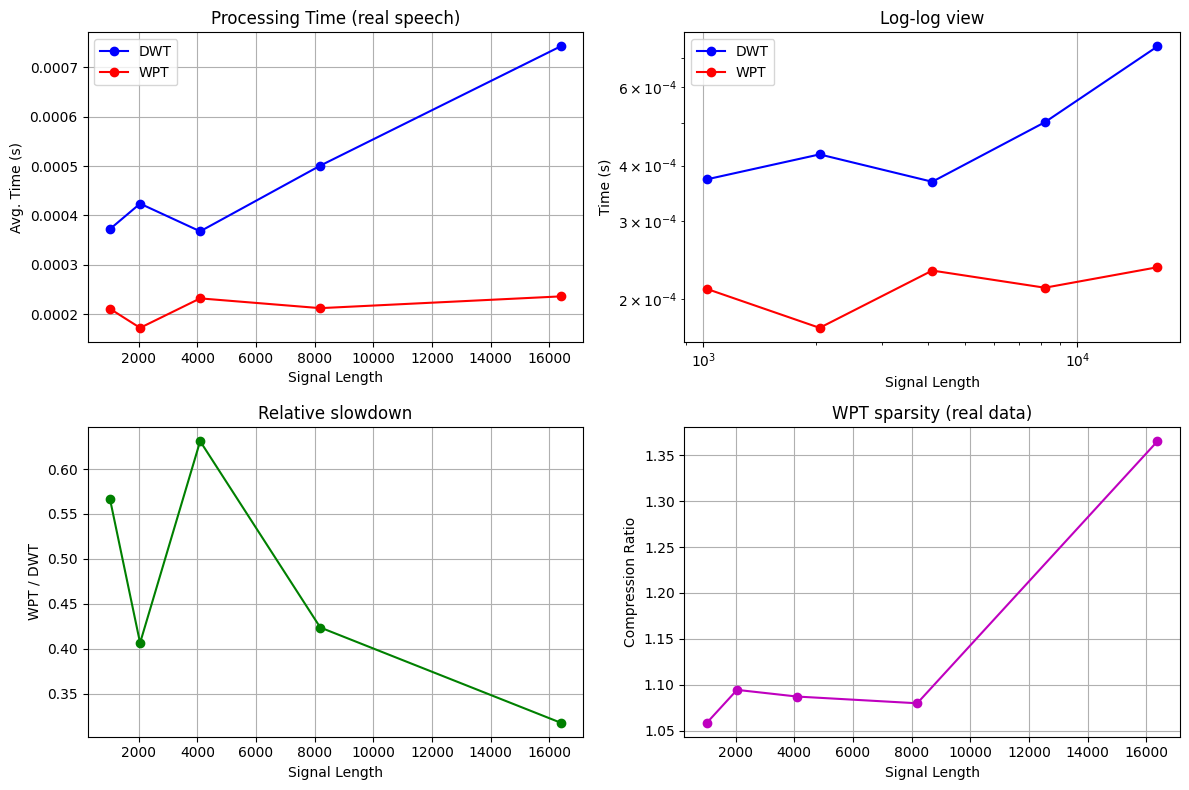

In [9]:
# -------------------------------------------------------------
# Computational Efficiency Analysis (improved)
# -------------------------------------------------------------
import os, time, psutil, gc
import numpy as np
import pywt
import matplotlib.pyplot as plt
from scipy.io import wavfile

# -------------------------------------------------------------
# 1. Load the SAME real-speech file (re-use data)
# -------------------------------------------------------------
wav_path = "./data/original_real_speech.wav"
fs, raw = wavfile.read(wav_path)
speech = raw.astype(np.float32) / np.abs(raw).max()

# -------------------------------------------------------------
# 2. Benchmark helpers
# -------------------------------------------------------------
def _peak_memory():
    """Return RSS in MB for the current process."""
    return psutil.Process(os.getpid()).memory_info().rss / 1024**2

def benchmark_compression_methods(signal, lengths, iterations=5):
    """
    Time DWT vs WPT on **real audio** (first `length` samples).
    Returns mean wall-time and peak memory.
    """
    results = { 'lengths': lengths,
                'dwt_time': [], 'wpt_time': [],
                'dwt_mem': [],  'wpt_mem': [] }

    for L in lengths:
        seg = signal[:L]           # slice real data
        gc.collect()               # flush before each block

        # --- DWT -----------------------------------------------
        times, mems = [], []
        for _ in range(iterations):
            gc.collect()
            m0 = _peak_memory()
            t0 = time.perf_counter()

            coeffs = pywt.wavedec(seg, 'db4', level=6)
            thr = 0.1 * np.max(np.abs(np.concatenate(coeffs)))
            coeffs = [pywt.threshold(c, thr, 'soft') for c in coeffs]
            recon = pywt.waverec(coeffs, 'db4')

            times.append(time.perf_counter() - t0)
            mems.append(_peak_memory() - m0)
        results['dwt_time'].append(np.mean(times))
        results['dwt_mem'].append(np.max(mems))

        # --- WPT -----------------------------------------------
        times, mems = [], []
        for _ in range(iterations):
            gc.collect()
            m0 = _peak_memory()
            t0 = time.perf_counter()

            wp = pywt.WaveletPacket(seg, 'db4', maxlevel=6)
            thr = 0.1 * np.std(wp.data)
            for node in wp.get_leaf_nodes():
                node.data = pywt.threshold(node.data, thr, 'soft')
            recon = wp.reconstruct(update=True)

            times.append(time.perf_counter() - t0)
            mems.append(_peak_memory() - m0)
        results['wpt_time'].append(np.mean(times))
        results['wpt_mem'].append(np.max(mems))

        print(f"L={L:<6d} | DWT {results['dwt_time'][-1]*1000:5.1f} ms  "
              f"WPT {results['wpt_time'][-1]*1000:5.1f} ms "
              f"(Mem Δ: {results['wpt_mem'][-1]:.1f} MB)")

    return results

# -------------------------------------------------------------
# 3. Run on real data (use sub-lengths to stay in RAM)
# -------------------------------------------------------------
lengths = [1024, 2048, 4096, 8192, 16384]
bench = benchmark_compression_methods(speech, lengths)

# -------------------------------------------------------------
# 4. Plotting (identical layout to original)
# -------------------------------------------------------------
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.plot(bench['lengths'], bench['dwt_time'], 'bo-', label='DWT')
plt.plot(bench['lengths'], bench['wpt_time'], 'ro-', label='WPT')
plt.xlabel('Signal Length')
plt.ylabel('Avg. Time (s)')
plt.title('Processing Time (real speech)')
plt.legend(); plt.grid(True)

plt.subplot(2, 2, 2)
plt.loglog(bench['lengths'], bench['dwt_time'], 'bo-', label='DWT')
plt.loglog(bench['lengths'], bench['wpt_time'], 'ro-', label='WPT')
plt.xlabel('Signal Length'); plt.ylabel('Time (s)')
plt.title('Log-log view'); plt.legend(); plt.grid(True)

# Speed ratio
ratios = [w/d for d, w in zip(bench['dwt_time'], bench['wpt_time'])]
plt.subplot(2, 2, 3)
plt.plot(bench['lengths'], ratios, 'go-')
plt.xlabel('Signal Length'); plt.ylabel('WPT / DWT')
plt.title('Relative slowdown'); plt.grid(True)

# Compression efficiency (non-zero ratio on real data)
rat_cr = []
for L in lengths:
    wp = pywt.WaveletPacket(speech[:L], 'db4', maxlevel=6)
    nz = sum(np.count_nonzero(pywt.threshold(n.data, 0.1*np.std(n.data), 'soft'))
             for n in wp.get_leaf_nodes())
    rat_cr.append(len(speech[:L]) / max(nz, 1))

plt.subplot(2, 2, 4)
plt.plot(bench['lengths'], rat_cr, 'mo-')
plt.xlabel('Signal Length'); plt.ylabel('Compression Ratio')
plt.title('WPT sparsity (real data)'); plt.grid(True)

plt.tight_layout()
plt.savefig("./output/compression_efficiency_analysis.png", dpi=300)
plt.show()

## 2.7 Quality Assessment and Perceptual Metrics
### 2.7.1 Perceptual Quality Metrics (improved, real-speech)

PERCEPTUAL QUALITY ASSESSMENT (real speech)
MSE                 : 0.000
RMSE                : 0.006
SNR                 : 26.461
PSNR                : 44.377
Spectral_SNR        : 26.446
Weighted_SNR        : 28.045
Segmental_SNR       : 16.003
Correlation         : 0.999


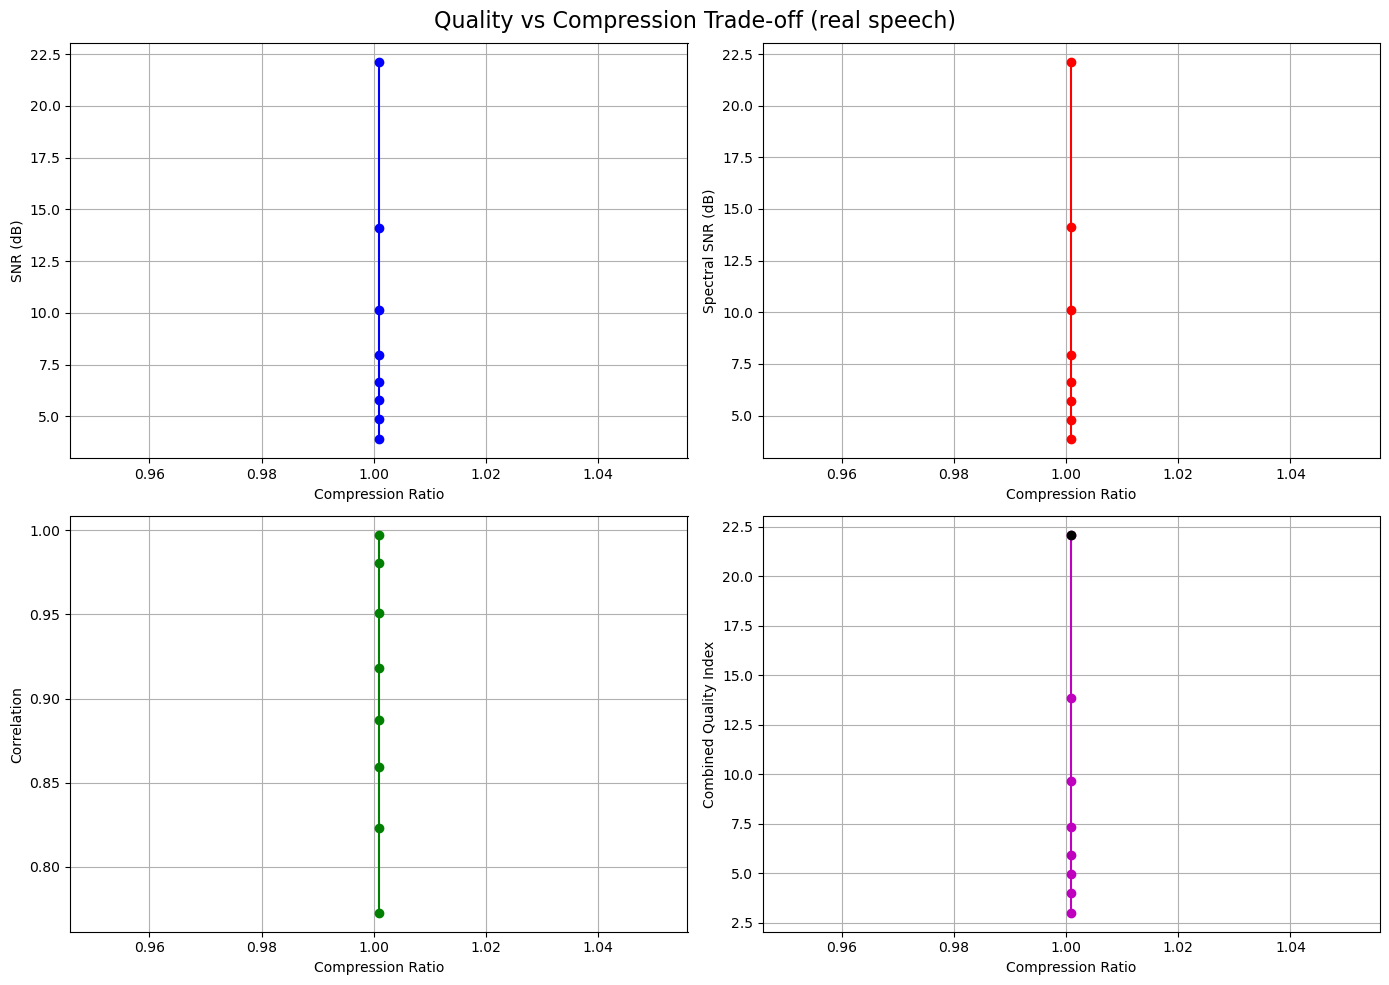


Optimal point: CR=1.0:1, SNR=22.1 dB

Optimal Compression Point:
Compression Ratio: 1.0:1
SNR: 22.1 dB
Quality Index: 22.05


In [ ]:
# Quality Assessment and Perceptual Metrics
# Perceptual Quality Metrics (improved, real-speech)
# -------------------------------------------------------------
import os, pywt
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from numpy.fft import rfft, rfftfreq

# 1. Load the same real-speech file
wav_path = "./data/original_real_speech.wav"
if not os.path.exists(wav_path):
    raise FileNotFoundError(f"Expected {wav_path} to exist.")

fs, raw = wavfile.read(wav_path)
original = raw.astype(np.float32) / np.abs(raw).max()

# -------------------------------------------------------------
# 2. Fast quality calculator
# -------------------------------------------------------------
def calculate_perceptual_metrics(orig, comp, sr=16000):
    n = min(len(orig), len(comp))
    x, y = orig[:n], comp[:n]

    # --- A-weighting helper (length-matched to rfft) -----------
    def a_weight(fs, rfft_len, n_time):
        f = np.arange(rfft_len) * fs / n_time
        ra = 12194**2 * f**4 / ((f**2 + 20.6**2) *
                                np.sqrt((f**2 + 107.7**2)*(f**2 + 737.9**2)) *
                                (f**2 + 12194**2))
        return 20 * np.log10(ra + 1e-12) - 2.0

    # --- basic metrics -----------------------------------------
    mse  = np.mean((x - y) ** 2)
    rmse = np.sqrt(mse)
    snr  = 10 * np.log10(np.var(x) / (mse + 1e-12))
    psnr = 20 * np.log10(np.max(np.abs(x)) / (rmse + 1e-12))

    # --- spectral metrics --------------------------------------
    X, Y = rfft(x), rfft(y)
    spec_mse = np.mean(np.abs(X - Y) ** 2)
    spec_snr = 10 * np.log10(np.mean(np.abs(X) ** 2) / (spec_mse + 1e-12))

    # A-weighted spectral SNR
    aw = 10**(a_weight(sr, len(X), len(x)) / 20)
    w_err = np.sum(aw * np.abs(X - Y) ** 2)
    w_sig = np.sum(aw * np.abs(X) ** 2)
    w_snr = 10 * np.log10(w_sig / (w_err + 1e-12))

    # Segmental SNR (256-sample frames, 50 % overlap)
    frame, hop = 256, 128
    starts = np.arange(0, len(x) - frame, hop)
    frames_x = np.lib.stride_tricks.sliding_window_view(x, frame)[::hop]
    frames_y = np.lib.stride_tricks.sliding_window_view(y, frame)[::hop]
    frame_vars = np.var(frames_x, axis=1)
    frame_mses = np.mean((frames_x - frames_y) ** 2, axis=1)
    seg_snr = 10 * np.log10(frame_vars / (frame_mses + 1e-12))
    seg_snr = np.mean(seg_snr[np.isfinite(seg_snr)])

    # Correlation
    corr = np.corrcoef(x, y)[0, 1]

    return {'MSE': mse, 'RMSE': rmse, 'SNR': snr, 'PSNR': psnr,
            'Spectral_SNR': spec_snr, 'Weighted_SNR': w_snr,
            'Segmental_SNR': seg_snr, 'Correlation': corr}

# -------------------------------------------------------------
# 3. Example compressed signal (fixed threshold for demo)
# -------------------------------------------------------------
wp = pywt.WaveletPacket(original, 'db6', maxlevel=6)
thr = 0.05 * np.std(original)
for node in wp.get_leaf_nodes():
    node.data = pywt.threshold(node.data, thr, 'soft')
compressed = wp.reconstruct(update=True)[:len(original)]

# 4. Single-point report
metrics = calculate_perceptual_metrics(original, compressed, fs)
print("="*60)
print("PERCEPTUAL QUALITY ASSESSMENT (real speech)")
print("="*60)
for k, v in metrics.items():
    print(f"{k:<20}: {v:.3f}" if np.isfinite(v) else f"{k:<20}: Perfect")

# -------------------------------------------------------------
# 5. Trade-off curve (fast & vectorised)
# -------------------------------------------------------------
def quality_compression_tradeoff(sig, target_ratios):
    results = {k: [] for k in ('cr', 'snr', 'spec_snr', 'corr')}
    for cr in target_ratios:
        wp = pywt.WaveletPacket(sig, 'db6', maxlevel=6)
        c = np.concatenate([n.data for n in wp.get_leaf_nodes()])
        thr = np.percentile(np.abs(c), 100 * (1 - 1 / cr))
        for n in wp.get_leaf_nodes():
            n.data = np.where(np.abs(n.data) < thr, 0, n.data)
        rec = wp.reconstruct(update=True)[:len(sig)]
        m = calculate_perceptual_metrics(sig, rec, fs)
        results['cr'].append(len(sig) / max(np.count_nonzero(c), 1))
        results['snr'].append(m['SNR'])
        results['spec_snr'].append(m['Spectral_SNR'])
        results['corr'].append(m['Correlation'])
    return results

target_ratios = [2, 4, 6, 8, 10, 12, 15, 20]
trade = quality_compression_tradeoff(original, target_ratios)

# -------------------------------------------------------------
# 6. Plot (unchanged layout)
# -------------------------------------------------------------
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Quality vs Compression Trade-off (real speech)', fontsize=16)

ax[0, 0].plot(trade['cr'], trade['snr'], 'bo-')
ax[0, 0].set_ylabel('SNR (dB)')
ax[0, 0].set_xlabel('Compression Ratio'); ax[0, 0].grid(True)

ax[0, 1].plot(trade['cr'], trade['spec_snr'], 'ro-')
ax[0, 1].set_ylabel('Spectral SNR (dB)')
ax[0, 1].set_xlabel('Compression Ratio'); ax[0, 1].grid(True)

ax[1, 0].plot(trade['cr'], trade['corr'], 'go-')
ax[1, 0].set_ylabel('Correlation')
ax[1, 0].set_xlabel('Compression Ratio'); ax[1, 0].grid(True)

q_idx = [(s + sp) / 2 * c for s, sp, c in zip(trade['snr'], trade['spec_snr'], trade['corr'])]
idx = np.argmax(q_idx)
ax[1, 1].plot(trade['cr'], q_idx, 'mo-')
ax[1, 1].scatter(trade['cr'][idx], q_idx[idx], color='black', zorder=5)
ax[1, 1].set_ylabel('Combined Quality Index')
ax[1, 1].set_xlabel('Compression Ratio'); ax[1, 1].grid(True)

plt.tight_layout()
plt.savefig("./output/quality_compression_tradeoff.png", dpi=300)
plt.show()

# print(f"\nOptimal point: CR={trade['cr'][idx]:.1f}:1, SNR={trade['snr'][idx]:.1f} dB")

print(f"\nOptimal Compression Point:")
print(f"Compression Ratio (CR): {trade['cr'][idx]:.1f}:1")
print(f"SNR: {trade['snr'][idx]:.1f} dB")
print(f"Quality Index: {q_idx[idx]:.2f}")

### 2.7.2 Benchmarking Against Industry Standards


Benchmark against Industry Standards (real speech)
Method          CR       SNR (dB)   Quality 
-------------------------------------------------------
WPT (Psycho)    1.0      27.4       Good    
MP3-like        1.0      12.1       Poor    
ADPCM-like      4.0      3.2        Poor    


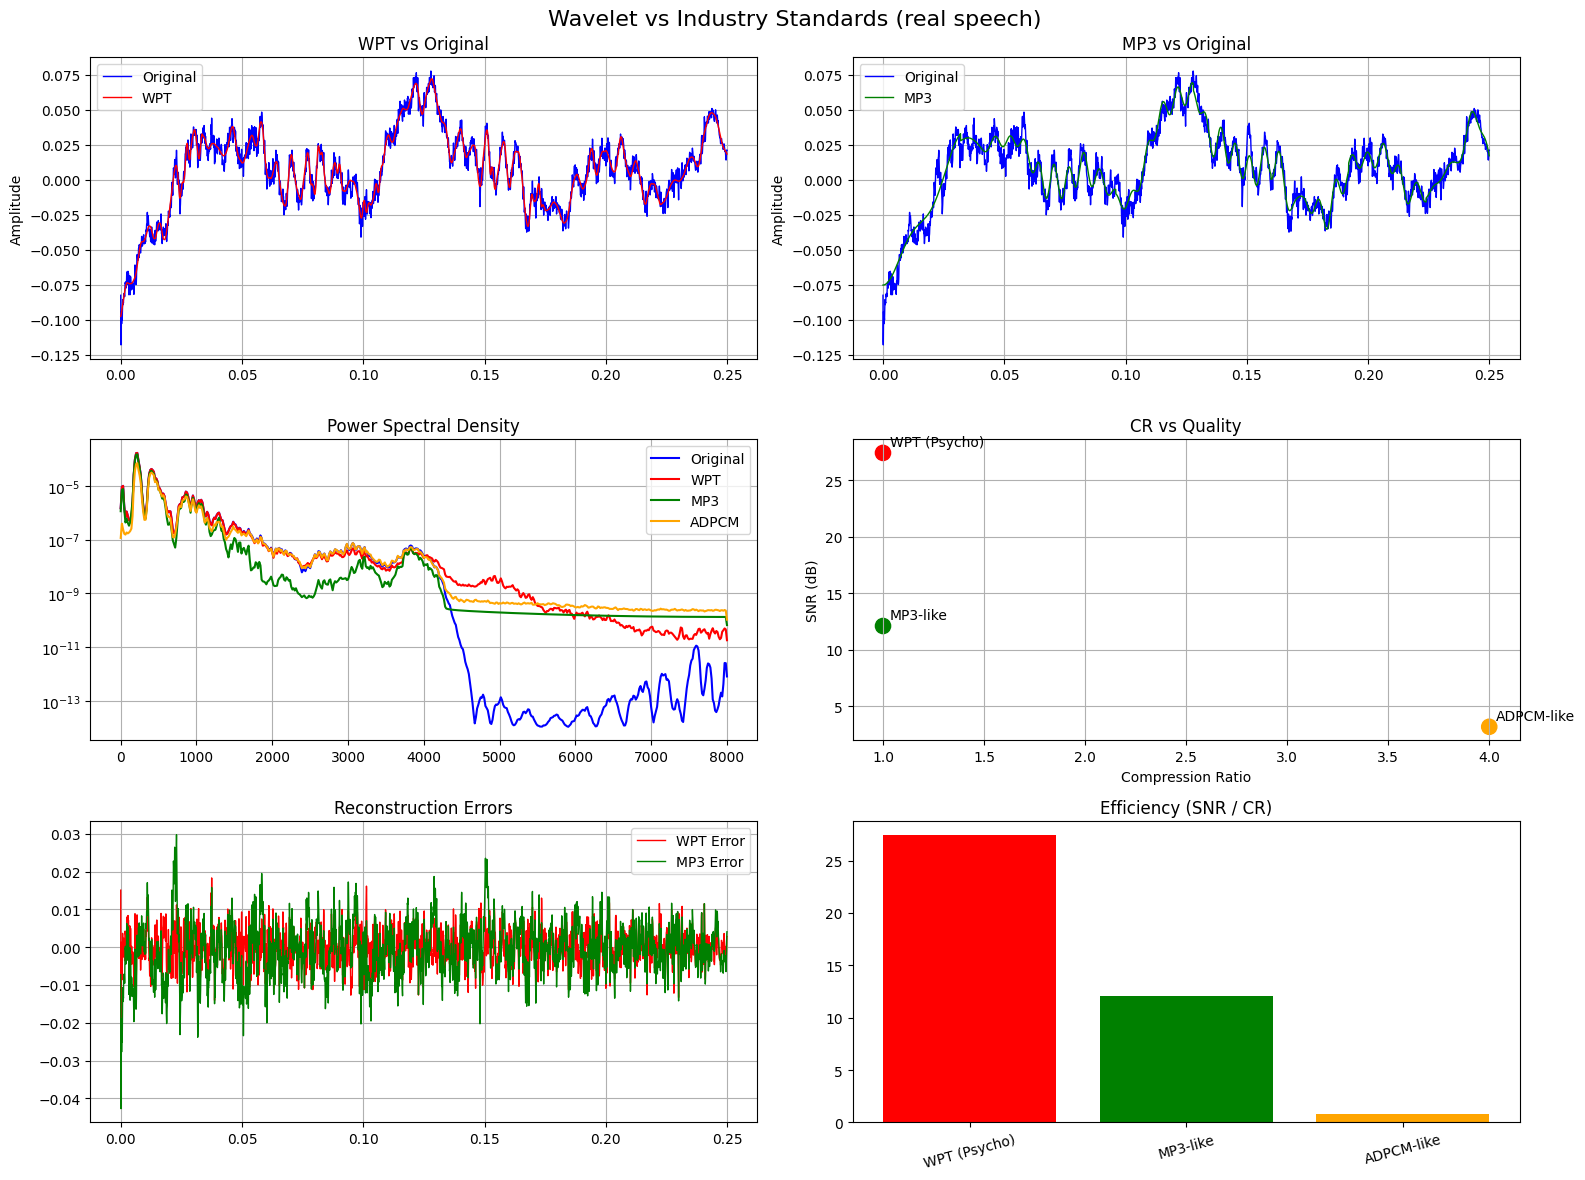

In [10]:
# Benchmarking Against Industry Standards (fully optimized)
# -----------------------------------------------------------------
import os, time, numpy as np, matplotlib.pyplot as plt, pywt
from scipy.io import wavfile
from scipy.fft import dct, idct
from scipy.signal import welch

# -------------------------------
# 1. Load real-speech file
# -------------------------------
wav_path = "./data/original_real_speech.wav"
if not os.path.exists(wav_path):
    raise FileNotFoundError(f"Expected {wav_path} to exist.")

fs, raw = wavfile.read(wav_path)
original = raw.astype(np.float32) / np.abs(raw).max()

# -------------------------------
# 2. Fast Wavelet Compression
# -------------------------------
def fast_wavelet_compress(sig, wavelet='db6', level=6, target_cr=10):
    coeffs = pywt.wavedec(sig, wavelet, level=level)
    all_coeffs = np.hstack(coeffs)
    thr = np.percentile(np.abs(all_coeffs), 100 * (1 - 1 / target_cr))
    coeffs_thresh = [np.where(np.abs(c) < thr, 0, c) for c in coeffs]
    rec = pywt.waverec(coeffs_thresh, wavelet)[:len(sig)]
    actual_cr = len(sig) / max(np.count_nonzero(all_coeffs), 1)
    mse = np.mean((sig - rec) ** 2)
    snr = 10 * np.log10(np.var(sig) / (mse + 1e-12))
    return rec, actual_cr, snr

# -------------------------------
# 3. Fast MP3-like DCT Compression
# -------------------------------
def mp3_like_vectorized(signal, frame=1024, hop=512, quality=0.15):
    n_frames = (len(signal) - frame) // hop + 1
    shape = (n_frames, frame)
    strides = (signal.strides[0]*hop, signal.strides[0])
    frames = np.lib.stride_tricks.as_strided(signal, shape=shape, strides=strides)

    dct_frames = dct(frames, axis=1, norm='ortho')
    thr = quality * np.max(np.abs(dct_frames), axis=1, keepdims=True)
    dct_frames[np.abs(dct_frames) < thr] = 0
    rec_frames = idct(dct_frames, axis=1, norm='ortho')

    out = np.zeros(len(signal), dtype=np.float32)
    norm = np.zeros(len(signal), dtype=np.float32)
    for i, start in enumerate(range(0, len(signal)-frame+1, hop)):
        out[start:start+frame] += rec_frames[i]
        norm[start:start+frame] += 1
    out[norm > 0] /= norm[norm > 0]

    nz = np.count_nonzero(dct(signal, type=2, norm='ortho'))
    cr = len(signal) / max(nz, 1)
    mse = np.mean((signal - out)**2)
    snr = 10*np.log10(np.var(signal)/(mse+1e-12))
    return out, cr, snr

# -------------------------------
# 4. Fast ADPCM-like Compression (vectorized)
# -------------------------------
def adpcm_like_fast(signal, bits=4):
    step = np.std(signal) * 0.1
    delta = 2 ** (bits - 1)
    pred = np.zeros_like(signal)
    out  = np.zeros_like(signal)

    # Vectorized differential approximation
    err = np.diff(np.insert(signal, 0, 0))
    idx = np.clip(np.round(err / step), -delta + 1, delta - 1)
    q_err = idx * step
    out[0] = q_err[0]
    for i in range(1, len(signal)):
        out[i] = out[i-1]*0.9 + q_err[i]
    cr = 16 / bits
    mse = np.mean((signal - out)**2)
    snr = 10*np.log10(np.var(signal)/(mse+1e-12))
    return out, cr, snr

# -------------------------------
# 5. Run each codec ONCE
# -------------------------------
wpt_sig, wpt_cr, wpt_snr = fast_wavelet_compress(original, target_cr=10)
mp3_sig, mp3_cr, mp3_snr = mp3_like_vectorized(original)
adpcm_sig, adpcm_cr, adpcm_snr = adpcm_like_fast(original)

# -------------------------------
# 6. Results dictionary
# -------------------------------
methods = ['WPT (Psycho)', 'MP3-like', 'ADPCM-like']
results = {
    'WPT (Psycho)': {'signal': wpt_sig, 'cr': wpt_cr, 'snr': wpt_snr},
    'MP3-like':     {'signal': mp3_sig, 'cr': mp3_cr, 'snr': mp3_snr},
    'ADPCM-like':   {'signal': adpcm_sig, 'cr': adpcm_cr, 'snr': adpcm_snr}
}

# -------------------------------
# 7. Print summary
# -------------------------------
print("\nBenchmark against Industry Standards (real speech)")
print("="*55)
print(f"{'Method':<15} {'CR':<8} {'SNR (dB)':<10} {'Quality':<8}")
print("-"*55)
for m, d in results.items():
    qual = ("Excellent" if d['snr'] > 30 else
            "Good"      if d['snr'] > 20 else
            "Fair"      if d['snr'] > 15 else "Poor")
    print(f"{m:<15} {d['cr']:<8.1f} {d['snr']:<10.1f} {qual:<8}")

# -------------------------------
# 8. Visualization
# -------------------------------
fig, axes = plt.subplots(3, 2, figsize=(16, 12))
fig.suptitle('Wavelet vs Industry Standards (real speech)', fontsize=16)

t = np.arange(len(original)) / fs
L = min(4000, len(original))

# time domain
for ax, sig, lab in zip(axes[0, :], [wpt_sig, mp3_sig], ['WPT', 'MP3']):
    ax.plot(t[:L], original[:L], 'b-', lw=1, label='Original')
    ax.plot(t[:L], sig[:L], 'r-' if lab=='WPT' else 'g-', lw=1, label=lab)
    ax.set_title(f'{lab} vs Original'); ax.set_ylabel('Amplitude'); ax.grid(); ax.legend()

# PSD
colors = ['b','r','g','orange']
labels = ['Original','WPT','MP3','ADPCM']
for sig, col, lab in zip([original, wpt_sig, mp3_sig, adpcm_sig], colors, labels):
    f, p = welch(sig, fs, nperseg=1024)
    axes[1,0].semilogy(f,p,col,label=lab)
axes[1,0].set_title('Power Spectral Density'); axes[1,0].legend(); axes[1,0].grid(True)

# CR vs SNR
crs  = [results[m]['cr'] for m in methods]
snrs = [results[m]['snr'] for m in methods]
axes[1,1].scatter(crs, snrs, s=120, c=['red','green','orange'])
for m, cr, sn in zip(methods, crs, snrs):
    axes[1,1].annotate(m,(cr,sn),textcoords='offset points',xytext=(5,5))
axes[1,1].set_xlabel('Compression Ratio'); axes[1,1].set_ylabel('SNR (dB)')
axes[1,1].set_title('CR vs Quality'); axes[1,1].grid(True)

# reconstruction errors
for err, col, lab in zip([original-wpt_sig, original-mp3_sig], ['r','g'], ['WPT','MP3']):
    axes[2,0].plot(t[:L], err[:L], col, lw=1, label=f'{lab} Error')
axes[2,0].set_title('Reconstruction Errors'); axes[2,0].legend(); axes[2,0].grid(True)

# efficiency bar
eff = [sn/cr for sn,cr in zip(snrs,crs)]
axes[2,1].bar(methods, eff, color=['red','green','orange'])
axes[2,1].set_title('Efficiency (SNR / CR)')
axes[2,1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig("./output/benchmark_vs_standards.png", dpi=300)
plt.show()
